**Import block**

In [9]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
import pandas as pd

**Locate the RIS drive on this computer**

In [8]:
import os

DRIVE_ROOT = "Y:/PhysiologyBasalGanglia" #Y aka the name of "Friedman_Lab"

print(os.listdir(DRIVE_ROOT))

['.DS_Store', '.git', '.gitignore', '.venv', '.venvPC', 'code', 'dataset_description.json', 'derivatives', 'ingest', 'INTERACTIVE_GUIDE.md', 'participants.json', 'participants.tsv', 'phenotype', 'README.md', 'requirements.txt', 'restricted_templates', 'secure', 'sourcedata', 'structure.txt', 'sub-BG0001', 'sub-BG0002', 'sub-BG0003', 'sub-BG0004', 'sub-BG0005', 'sub-BG0006', 'sub-BG0007', 'sub-BG0008', 'sub-BG0009', 'sub-BG0010', 'sub-BG0011', 'sub-BG0012', 'sub-BG0013', 'sub-BG0014', 'sub-BG0015', 'sub-BG0016', 'sub-BG0017', 'sub-BG0018', 'sub-BG0019', 'sub-BG0020', 'sub-BG0021']


**Interact with participant data**

In [67]:
file_path = os.path.join(DRIVE_ROOT, "participants.tsv")

participants = pd.read_csv(file_path, sep="\t")

# print(participants.head()) #21 is the full number of participants thus far

participants = [
    participants["participant_id"] == "sub-BG0011"
]

# print(participants)


'''
Participant and clinical tables
participants.tsv — one row per participant
phenotype/clinical.tsv
phenotype/medications.tsv
phenotype/assessments.tsv
Restricted identifiable information — do not distribute
secure/participant_key.tsv — links participant IDs to identities
'''
print("clinical phenotype")

phenotype_file_path = os.path.join(DRIVE_ROOT, "phenotype/clinical.tsv")

clinical_phenotype = pd.read_csv(phenotype_file_path, sep="\t") #where \t represents a tab character. 

# print(clinical_phenotype.head(11))


print("printing the query....")
dbs_case = clinical_phenotype.query(
    "session_id == 'ses-dbs01' and procedure == 'DBS'"
)

print(dbs_case)



clinical phenotype
printing the query....
   participant_id session_id   diagnosis procedure target clinical_notes_code
10     sub-BG0011  ses-dbs01  Parkinsons       DBS    GPi                 NaN


**Find BIDS data associated with DBS case**

In [46]:
# subject_number = "sub-BG0011"

# BIDS_data_path = os.path.join(DRIVE_ROOT, subject_number)

# for root, dir, files in os.walk(BIDS_data_path):
#     print(root),
#     # print(dir)
#     for file in files:
#         print("\t", file)


# sessions_file_path = os.path.join(BIDS_data_path, "sub-BG0011_sessions.tsv")

# sessions = pd.read_csv(sessions_file_path, sep="\t")

# print(sessions)
# #just exposes the target, laterality, location, and the dbs_state. 




In [66]:
# running it back

print(DRIVE_ROOT)

participant = "sub-BG0011"

DBS_case_path = os.path.join(DRIVE_ROOT, participant)

print(DBS_case_path)
print(os.listdir(DBS_case_path))

session_file_path = os.path.join(DBS_case_path, "ses-dbs01")
print(session_file_path)

for root, dir, files in os.walk(session_file_path):
    print(root),
    # print(dir),
    for file in files:
        print("\t", file)



#looking into the TSV files

'''
I have to:

load the tsv file:
pd.read_csv(x, sep="\t")

tsv means "tab separated values"

'''

sessions_file_path1 = os.path.join(DBS_case_path, "sub-BG0011_sessions.tsv")

csv_sessions_tsv = pd.read_csv(sessions_file_path1, sep="\t")

print(csv_sessions_tsv.head())

query_gpi = csv_sessions_tsv.query(
    "target == 'GPi'"
)


print("printing the query....")
print(query_gpi)
#returns everything.... and since this is the only patient, and all she had was gpi, it will return the same 1 row. 


Y:/PhysiologyBasalGanglia
Y:/PhysiologyBasalGanglia\sub-BG0011
['ses-dbs01', 'sub-BG0011_sessions.tsv']
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01\ieeg
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_channels.tsv
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_events.json
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_events.tsv
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.edf
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.json
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01\motion
	 sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_channels.tsv
	 sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.json
	 sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv
  session_id session_type  clinic_session_type procedure medication_state  \
0  ses-dbs01          dbs                  NaN       DBS              OFF   

   dbs_state target  procedu

**Load the joystick movement data**

In [74]:
MOTION_PATH = os.path.join(DBS_case_path, "ses-dbs01/motion")

print(os.listdir(MOTION_PATH))

PATH_TO_MOTION_JSON = os.path.join(MOTION_PATH, "sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.json" )

read_motion_json = pd.read_json(PATH_TO_MOTION_JSON)

print(read_motion_json)

#json is just a record of what happened to the data when it was converted. 
`

['sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_channels.tsv', 'sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.json', 'sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv']
                         TaskName  SamplingFrequency  \
CursorX                visuomotor               1375   
CursorY                visuomotor               1375   
DriveDepth             visuomotor               1375   
FilePart               visuomotor               1375   
Introduction           visuomotor               1375   
JoystickXpos           visuomotor               1375   
JoystickYpos           visuomotor               1375   
NeuroOmegaTimeStamp    visuomotor               1375   
Notes                  visuomotor               1375   
Port1                  visuomotor               1375   
Port1Time              visuomotor               1375   
Port2                  visuomotor               1375   
Port2Time              visuomotor       

**read the tsv motion data**

In [104]:
from IPython.display import display

MOTION_PATH = os.path.join(DBS_case_path, "ses-dbs01/motion")

print(os.listdir(MOTION_PATH))

PATH_TO_MOTION_TSV = os.path.join(MOTION_PATH, "sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv" )

read_motion_tsv = pd.read_csv(
    PATH_TO_MOTION_TSV,
    sep="\t",
    header=None #you can specify a header so it doesn't disrupt your first row of data. 
    
)

# print(read_motion_tsv.head().style)

# read_motion_tsv.head(10).style.format(precision=2).set_caption("Motion Data")


# display(read_motion_tsv)

# display(read_motion_tsv[0])

# print((read_motion_tsv[2])) #this actually only works since the label of the tsv col is 0 or 1 or 2. If it was named something else it wouldn't work

print("trying iloc....")

#try out iloc, seems to be better
print(read_motion_tsv.iloc[0, 0])

#json is just a record of what happened to the data when it was converted. 


['sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_channels.tsv', 'sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.json', 'sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv']
trying iloc....
512


Trying to look up int values in another cell, since we don't want to be loading every value in the dataframe everytime we're looking for a max() val. 

In [113]:
pd.set_option('display.max.columns', None) # None means no limit on the options here
# pd.set_option('display.max.rows', None) # prolly don't want the smoke.
pd.reset_option('display.max.columns')
pd.reset_option("display.max.rows")

pd.set_option('display.max.columns', None) # None means no limit on the options here


display(read_motion_tsv.head(5))


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
0,512,512,0,1,0,0,0,35896,0,0,0,0,0,0,0,0,0,0,0,1,1,54725,0,0,0,0,4294967295
1,512,512,0,1,0,0,0,35896,0,0,0,0,0,0,0,0,0,0,0,1,1,54725,0,0,0,0,4294967295
2,512,512,0,1,0,0,0,35896,0,0,0,0,0,0,0,0,0,0,0,1,1,54725,0,0,0,0,4294967295
3,512,512,0,1,0,0,0,35896,0,0,0,0,0,0,0,0,0,0,0,1,1,54725,0,0,0,0,4294967295
4,512,512,0,1,0,19275,15679,35903,0,0,0,0,0,0,0,0,0,0,0,1,1,54725,0,0,0,0,4294967295


**get paths for both ieeg and motion data**

In [133]:
# what is the BIDS path again?

print(DBS_case_path)

# find out what subfiles live in DBS case

for root, dir, files in os.walk(DBS_case_path):
    print(root),
    for file in files:
        print("\t", file)


IEEG_PATH = os.path.join(DBS_case_path, "ses-dbs01/ieeg/sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.edf")
JOYSTICK_PATH = os.path.join(DBS_case_path, "ses-dbs01/motion/sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv")

print(IEEG_PATH, "\n", JOYSTICK_PATH)




print(os.path.isfile(JOYSTICK_PATH))


Y:/PhysiologyBasalGanglia\sub-BG0011
Y:/PhysiologyBasalGanglia\sub-BG0011
	 sub-BG0011_sessions.tsv
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01\ieeg
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_channels.tsv
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_events.json
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_events.tsv
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.edf
	 sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.json
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01\motion
	 sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_channels.tsv
	 sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.json
	 sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv
Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01/ieeg/sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.edf 
 Y:/PhysiologyBasalGanglia\sub-BG0011\ses-dbs01/motion/sub-BG0011_ses-dbs01_task-visuomotor_tracksys-joystick_run-01_motion.tsv


investigate EDF ieeg data using MNE

In [136]:
import mne 

raw = mne.io.read_raw_edf(IEEG_PATH, preload=False)
#min norm estimate
#input output

display(raw.info)

# print(raw.info)

Extracting EDF parameters from Y:\PhysiologyBasalGanglia\sub-BG0011\ses-dbs01\ieeg\sub-BG0011_ses-dbs01_task-visuomotor_run-01_ieeg.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...


<Info | 8 non-empty values
 bads: []
 ch_names: LFP 01, LFP 02, LFP 03, LFP 04, LFP 05, Macro LFP 01, Macro LFP ...
 chs: 10 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 687.5 Hz
 meas_date: 2026-10-12 21:11:41 UTC
 nchan: 10
 projs: []
 sfreq: 1375.0 Hz
 subject_info: 3 items (dict)
>

<Info | 8 non-empty values
 bads: []
 ch_names: LFP 01, LFP 02, LFP 03, LFP 04, LFP 05, Macro LFP 01, Macro LFP ...
 chs: 10 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 687.5 Hz
 meas_date: 2026-10-12 21:11:41 UTC
 nchan: 10
 projs: []
 sfreq: 1375.0 Hz
 subject_info: 3 items (dict)
>


investigating mne more

['LFP 01', 'LFP 02', 'LFP 03', 'LFP 04', 'LFP 05', 'Macro LFP 01', 'Macro LFP 02', 'Macro LFP 03', 'Macro LFP 04', 'Macro LFP 05'] 
 807125 
 1375.0 
 586.9992727272727


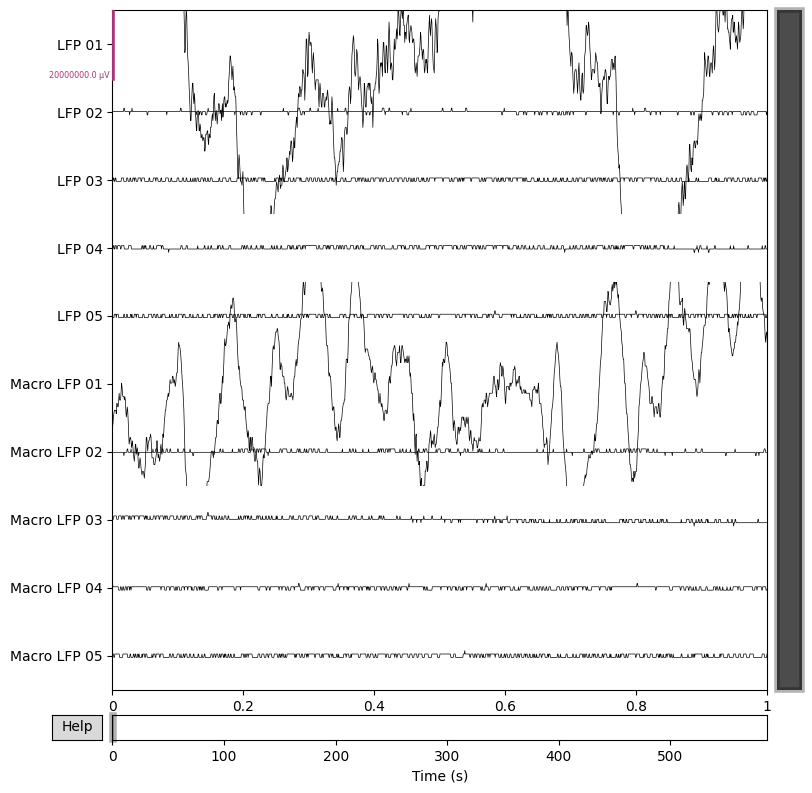

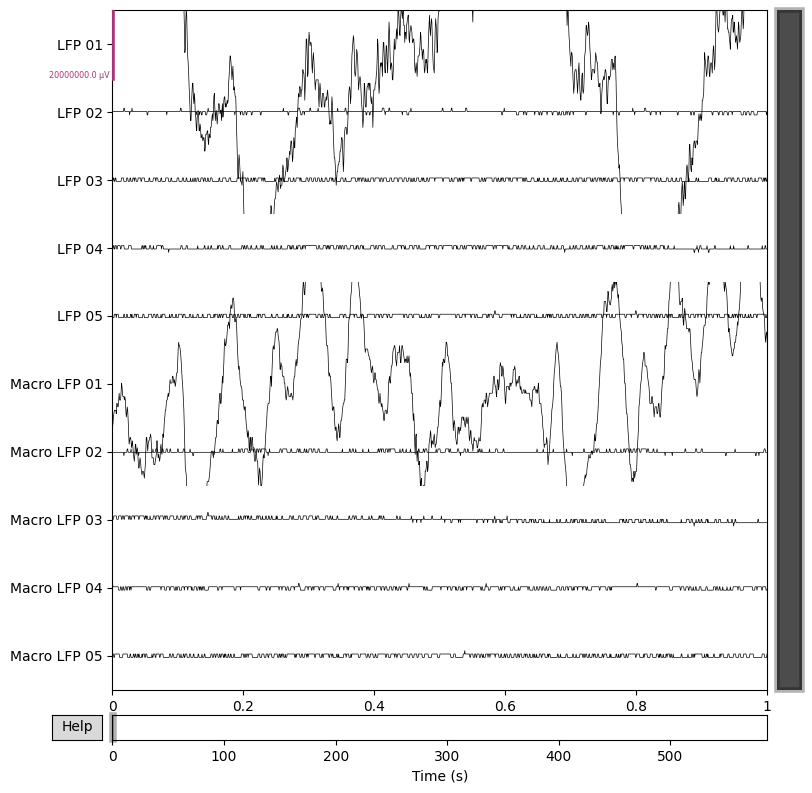

In [167]:
print(
    raw.ch_names,
    "\n",
    raw.n_times,
    "\n",
    raw.info['sfreq'],
    "\n",
    raw.times[-1] #always measured in seconds. 



)

raw.plot(
    duration = 1, #s
    #don't have to add n_channels, but:
    n_channels = 10, #all of them
    #scaling parm:
    scalings = {"eeg": 10000000e-6}
)

checking the signal amp

In [170]:
import numpy as np

data = raw.get_data(start = 0, stop = 6875)

for name, channel in zip(raw.ch_names, data):
    print(name, ";", np.ptp(channel) * 1e6, "uV")


channel = raw.get_data(picks=["LFP 03"], start=0, stop=6875)[0]

print("Minimum:", np.min(channel))
print("Maximum:", np.max(channel))
print("Median:", np.median(channel))
print("1st percentile:", np.percentile(channel, 1))
print("99th percentile:", np.percentile(channel, 99))

print(np.unique(channel, return_counts=True))

LFP 01 ; 209978179.59868774 uV
LFP 02 ; 2999923.7048905166 uV
LFP 03 ; 3000000.0 uV
LFP 04 ; 2999954.22293431 uV
LFP 05 ; 2000000.0 uV
Macro LFP 01 ; 119996459.90691997 uV
Macro LFP 02 ; 2999984.740978103 uV
Macro LFP 03 ; 4000000.0 uV
Macro LFP 04 ; 3000000.000000002 uV
Macro LFP 05 ; 2000000.0 uV
Minimum: -2.0
Maximum: 1.0
Median: 0.0
1st percentile: -1.0
99th percentile: 0.0
(array([-2., -1.,  0.,  1.]), array([   2, 3050, 3813,   10]))


In [174]:
import json

with open(IEEG_PATH.replace("_ieeg.edf", "_ieeg.json")) as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2))



channel = raw.get_data(picks=["LFP 01"], start=0, stop=6875)[0]

print("Min:", np.min(channel))
print("Max:", np.max(channel))
print("Unique values:", len(np.unique(channel)))
print("Standard deviation:", np.std(channel))


channels = pd.read_csv(
    IEEG_PATH.replace("_ieeg.edf", "_channels.tsv"),
    sep="\t"
)

display(channels[["name", "type", "units"]])


channels = pd.read_csv(
    IEEG_PATH.replace("_ieeg.edf", "_channels.tsv"),
    sep="\t",
    keep_default_na=False
)

display(channels)


{
  "TaskName": "visuomotor",
  "SamplingFrequency": 1375.0,
  "PowerLineFrequency": "n/a",
  "iEEGReference": "n/a",
  "RecordingDuration": 586.5090909090909,
  "EDFDataRecordDuration": 1.0,
  "EDFOriginalSampleCount": 806450,
  "EDFPaddedSampleCount": 807125,
  "EDFSyntheticPaddingSamples": 675,
  "EDFSyntheticPaddingDuration": 0.4909090909090909,
  "EDFSyntheticPaddingStartSample": 806450,
  "EDFSyntheticPaddingEndSample": 807125,
  "EDFSyntheticPaddingMethod": "Repeat final source sample",
  "EDFTrueRecordingDuration": 586.5090909090909,
  "RecordingType": "continuous",
  "SoftwareFilters": "n/a",
  "SourceFile": "sourcedata/sub-BG0011/ses-dbs01/bci2000/NameS001R04.dat",
  "NeuralSignalExported": true,
  "NeuralSignalExportDecision": "exported_as_ieeg",
  "DBSStimulation": "n/a"
}
Min: -115.99061570153349
Max: 93.98756389715427
Unique values: 211
Standard deviation: 38.74269122340555


,name,type,units
0,LFP 01,MISC,NaN
1,LFP 02,MISC,NaN
2,LFP 03,MISC,NaN
3,LFP 04,MISC,NaN
4,LFP 05,MISC,NaN
5,Macro LFP 01,MISC,NaN
6,Macro LFP 02,MISC,NaN
7,Macro LFP 03,MISC,NaN
8,Macro LFP 04,MISC,NaN
9,Macro LFP 05,MISC,NaN


,name,type,units,sampling_frequency,status,status_description
0,LFP 01,MISC,n/a,1375.0,n/a,n/a
1,LFP 02,MISC,n/a,1375.0,n/a,n/a
2,LFP 03,MISC,n/a,1375.0,n/a,n/a
3,LFP 04,MISC,n/a,1375.0,n/a,n/a
4,LFP 05,MISC,n/a,1375.0,n/a,n/a
5,Macro LFP 01,MISC,n/a,1375.0,n/a,n/a
6,Macro LFP 02,MISC,n/a,1375.0,n/a,n/a
7,Macro LFP 03,MISC,n/a,1375.0,n/a,n/a
8,Macro LFP 04,MISC,n/a,1375.0,n/a,n/a
9,Macro LFP 05,MISC,n/a,1375.0,n/a,n/a
